<a href="https://colab.research.google.com/github/Phils-dev/RAG_Homework/blob/main/PX4_RAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 드론 운용기록 분석 및 비행안전 기술문서 RAG 지원 시스템

- 과목 : 생성형 AI 활용
- 작성자 :
- 개발환경 : Google Colab, Python
- 대상기체 : Holybro X500 V2 + Pixhawk 6C
- 비행제어 소프트웨어 : PX4 Autopilot
- 기술문서 버전 : PX4 v1.17.0

## 개발 목적

PX4 공식 기술문서를 활용한 RAG 시스템을 구축하고,
드론 운용일지와 점검이력을 분석하여 정비 점검항목 및
비행안전 관련 기술정보를 제공한다.

※ 본 프로그램의 운용일지 및 정비주기 지침은
교육용 가상 데이터이며, 실제 비행 적합성 판단에 사용하지 않는다.

# PART 1. 개발 환경 구성

## 01. 개발 환경 설정

RAG 시스템 구축 및 드론 운용기록 분석에 필요한
Python 패키지를 설치한다.

In [2]:

# 패키지 설치
%pip install -q \
    "langchain>=1.0,<2.0" \
    "langchain-core>=1.4.7,<2.0" \
    "langchain-text-splitters>=1.1.2,<2.0" \
    langchain-openai \
    langchain-chroma \
    chromadb \
    langchain-huggingface \
    sentence-transformers \
    requests==2.32.4 \
    opentelemetry-api==1.42.1 \
    opentelemetry-sdk==1.42.1 \
    opentelemetry-exporter-otlp-proto-grpc==1.42.1 \
    "oauthlib>=3.2.0,<4" \
    jedi


In [2]:
# 패키지 의존성 검사
%pip check

No broken requirements found.


In [3]:
# 설치 환경 확인
import sys
from importlib.metadata import version

# Python 버전 출력
print("Python :", sys.version.split()[0])

# 패키지 목록 정의
packages = [
    "langchain",
    "langchain-core",
    "langchain-text-splitters",
    "langchain-openai",
    "langchain-chroma",
    "chromadb",
    "langchain-huggingface",
    "sentence-transformers",
    "pandas",
    "requests",
    "opentelemetry-api",
    "opentelemetry-sdk"
]

# 패키지 버전 출력
for package in packages:
    print(f"{package} : {version(package)}")

Python : 3.13.18
langchain : 1.4.8
langchain-core : 1.8.5
langchain-text-splitters : 1.2.0
langchain-openai : 1.8.5
langchain-chroma : 1.2.0
chromadb : 1.5.9
langchain-huggingface : 1.3.0
sentence-transformers : 5.7.0
pandas : 2.2.3
requests : 2.32.4
opentelemetry-api : 1.42.1
opentelemetry-sdk : 1.42.1



-----------------------------------------------------------



## 02. 라이브러리 불러오기

RAG 시스템 구축, 기술문서 처리, 운용일지 분석 및
점검 보고서 생성에 필요한 라이브러리를 불러온다.


In [4]:

# 기본 라이브러리
import os
import re
import json
import time
import hashlib
from pathlib import Path

# 데이터 분석 라이브러리
import pandas as pd

# Colab 라이브러리
from google.colab import userdata, files
from IPython.display import display, Markdown

# 문서 처리 라이브러리
from langchain_core.documents import Document
from langchain_text_splitters import MarkdownHeaderTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 임베딩 라이브러리
from langchain_huggingface import HuggingFaceEmbeddings
from transformers import AutoTokenizer

# 벡터 DB 라이브러리
from langchain_chroma import Chroma

# LLM 및 RAG 라이브러리
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# 라이브러리 로드 결과 출력
print("라이브러리 로드 완료")


라이브러리 로드 완료



## 03. 실행 환경 설정

OpenAI API 인증키, 임베딩 모델, LLM 모델 및
기술문서와 운용자료의 경로를 설정한다.


In [5]:

# OpenAI API Key 설정
api_key = userdata.get("OPENAI_API_KEY")

if not api_key:
    raise ValueError("OpenAI API Key를 등록하세요.")

os.environ["OPENAI_API_KEY"] = api_key

# API Key 설정 결과 출력
print("OpenAI API Key 설정 완료")


OpenAI API Key 설정 완료


In [6]:

# 기준 기체 설정
AIRCRAFT_MODEL = "Holybro X500 V2"
FLIGHT_CONTROLLER = "Pixhawk 6C"
FLIGHT_SOFTWARE = "PX4 Autopilot"

# PX4 문서 버전 설정
PX4_VERSION = "v1.17.0"

# 임베딩 모델 설정
EMBEDDING_MODEL = "intfloat/multilingual-e5-small"

# LLM 모델 설정
LLM_MODEL = "gpt-5.4-mini"

# 문서 분할 설정
CHUNK_SIZE = 350
CHUNK_OVERLAP = 40
MAX_TOKENS = 512

# 검색 문서 개수 설정
TOP_K = 3


In [7]:

# 프로젝트 경로 설정
PROJECT_DIR = Path("/content/PX4_RAG_Project")

# 세부 디렉터리 경로 설정
DOCUMENT_DIR = PROJECT_DIR / "documents"
DATA_DIR = PROJECT_DIR / "data"
DB_DIR = PROJECT_DIR / "chroma_db"
TEST_DIR = PROJECT_DIR / "tests"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# 디렉터리 목록 정의
directories = [
    DOCUMENT_DIR,
    DATA_DIR,
    DB_DIR,
    TEST_DIR,
    OUTPUT_DIR
]

# 디렉터리 생성
for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

# 프로젝트 경로 출력
print("프로젝트 디렉터리 생성 완료")
print(PROJECT_DIR)


프로젝트 디렉터리 생성 완료
/content/PX4_RAG_Project


In [8]:

# 실행 환경 설정 결과 출력
print("=" * 60)
print("PX4 RAG 실행 환경")
print("=" * 60)

print("대상 기체       :", AIRCRAFT_MODEL)
print("비행제어기      :", FLIGHT_CONTROLLER)
print("비행제어 SW     :", FLIGHT_SOFTWARE)
print("기술문서 버전   :", PX4_VERSION)
print("임베딩 모델     :", EMBEDDING_MODEL)
print("LLM 모델        :", LLM_MODEL)
print("청크 크기       :", CHUNK_SIZE)
print("청크 중복       :", CHUNK_OVERLAP)
print("최대 토큰       :", MAX_TOKENS)
print("검색 문서 개수  :", TOP_K)

print("-" * 60)

# 디렉터리 생성 상태 확인
for directory in directories:
    status = "정상" if directory.is_dir() else "오류"
    print(f"{directory.name:15s} : {status}")

print("=" * 60)


PX4 RAG 실행 환경
대상 기체       : Holybro X500 V2
비행제어기      : Pixhawk 6C
비행제어 SW     : PX4 Autopilot
기술문서 버전   : v1.17.0
임베딩 모델     : intfloat/multilingual-e5-small
LLM 모델        : gpt-5.4-mini
청크 크기       : 350
청크 중복       : 40
최대 토큰       : 512
검색 문서 개수  : 3
------------------------------------------------------------
documents       : 정상
data            : 정상
chroma_db       : 정상
tests           : 정상
outputs         : 정상



# PART 2. RAG 시스템 구축

## 04. 문서 로드 (Load)

PX4 공식 기술문서를 수집하고 문서의 버전,
출처, 라이선스 및 파일 무결성을 관리한다.

수집된 Markdown 문서를 읽어 RAG 검색에
사용할 Document 객체를 생성한다.

### 4.1. 공식 기술문서 수집


In [9]:

import requests
from datetime import datetime, timezone

# PX4 저장소 설정
PX4_REPOSITORY = "PX4/PX4-Autopilot"
PX4_COMMIT = "d6f12ad1c4f70ad3230afd7d86e971421e02fef4"

# 원본 URL 설정
RAW_URL = (
    f"https://raw.githubusercontent.com/"
    f"{PX4_REPOSITORY}/{PX4_COMMIT}"
)

# 문서 URL 설정
DOCS_URL = "https://docs.px4.io/v1.17/en"

# 라이선스 설정
LICENSE_NAME = "CC BY 4.0"
LICENSE_URL = "https://creativecommons.org/licenses/by/4.0/"

# 수집 대상 문서 정의
DOCUMENT_FILES = [
    "frames_multicopter/holybro_x500v2_pixhawk6c.md",
    "flight_controller/pixhawk6c.md",
    "config/safety_intro.md",
    "config/safety.md",
    "log/flight_review.md",
    "log/flight_log_analysis.md",
    "test_and_ci/test_flights.md"
]

print("수집 대상 문서 :", len(DOCUMENT_FILES))


수집 대상 문서 : 7


In [10]:

# 문서 다운로드 함수 정의
def download_document(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.content

# 문서 수집 결과 정의
downloaded_files = []
failed_files = []

# 공식 문서 다운로드
for relative_path in DOCUMENT_FILES:

    file_name = Path(relative_path).name
    source_path = f"docs/en/{relative_path}"
    source_url = f"{RAW_URL}/{source_path}"

    try:
        content = download_document(source_url)

        # Markdown 내용 확인
        text = content.decode("utf-8")

        if not text.strip():
            raise ValueError("빈 문서")

        # 문서 저장
        file_path = DOCUMENT_DIR / file_name
        file_path.write_bytes(content)

        # 문서 정보 저장
        downloaded_files.append({
            "file_name": file_name,
            "source_path": source_path,
            "source_url": source_url,
            "document_url": (
                f"{DOCS_URL}/{relative_path[:-3]}"
            ),
            "version": PX4_VERSION,
            "commit": PX4_COMMIT,
            "author": "PX4 Documentation Contributors",
            "license": LICENSE_NAME,
            "license_url": LICENSE_URL,
            "source_type": "official",
            "modified": False,
            "sha256": hashlib.sha256(content).hexdigest(),
            "size_bytes": len(content),
            "collected_at": datetime.now(
                timezone.utc
            ).isoformat()
        })

        print(f"[완료] {file_name}")

    except Exception as error:
        failed_files.append(relative_path)
        print(f"[실패] {file_name} : {error}")

# 다운로드 결과 출력
print("-" * 60)
print("다운로드 성공 :", len(downloaded_files))
print("다운로드 실패 :", len(failed_files))


[완료] holybro_x500v2_pixhawk6c.md
[완료] pixhawk6c.md
[완료] safety_intro.md
[완료] safety.md
[완료] flight_review.md
[완료] flight_log_analysis.md
[완료] test_flights.md
------------------------------------------------------------
다운로드 성공 : 7
다운로드 실패 : 0


In [11]:

# 라이선스 원본 URL 설정
license_source_url = f"{RAW_URL}/docs/LICENSE"

# 라이선스 파일 다운로드
license_content = download_document(license_source_url)

# 라이선스 유형 확인
if "CC BY 4.0" not in license_content.decode("utf-8"):
    raise ValueError("라이선스 유형 확인 필요")

# 라이선스 파일 저장
license_path = DOCUMENT_DIR / "LICENSE"
license_path.write_bytes(license_content)

print("라이선스 파일 저장 완료")
print(license_path)


라이선스 파일 저장 완료
/content/PX4_RAG_Project/documents/LICENSE


In [12]:

# 수집 결과 확인
if failed_files:
    raise RuntimeError("다운로드 실패 문서 확인 필요")

# 문서 관리 정보 정의
manifest = {
    "repository": PX4_REPOSITORY,
    "version": PX4_VERSION,
    "commit": PX4_COMMIT,
    "license": LICENSE_NAME,
    "license_source_url": license_source_url,
    "license_sha256": hashlib.sha256(
        license_content
    ).hexdigest(),
    "document_count": len(downloaded_files),
    "documents": downloaded_files
}

# Manifest 파일 경로 설정
manifest_path = DOCUMENT_DIR / "manifest.json"

# Manifest 파일 저장
with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Manifest 파일 저장 완료")


Manifest 파일 저장 완료


In [13]:

# 수집 문서 목록 생성
df_documents = pd.DataFrame(downloaded_files)

# 문서 크기 계산
df_documents["size_kb"] = (
    df_documents["size_bytes"] / 1024
).round(2)

# 문서 목록 출력
display(df_documents[
    ["file_name", "version", "license", "size_kb"]
])

# 문서 수집 결과 출력
print("수집 문서 개수 :", len(df_documents))
print("문서 저장 경로 :", DOCUMENT_DIR)


,file_name,version,license,size_kb
0,holybro_x500v2_pixhawk6c.md,v1.17.0,CC BY 4.0,9.40
1,pixhawk6c.md,v1.17.0,CC BY 4.0,8.37
2,safety_intro.md,v1.17.0,CC BY 4.0,1.22
3,safety.md,v1.17.0,CC BY 4.0,52.67
4,flight_review.md,v1.17.0,CC BY 4.0,21.72
5,flight_log_analysis.md,v1.17.0,CC BY 4.0,8.12
6,test_flights.md,v1.17.0,CC BY 4.0,1.61


수집 문서 개수 : 7
문서 저장 경로 : /content/PX4_RAG_Project/documents


In [14]:

import shutil

# 백업 파일 생성
backup_path = shutil.make_archive(
    "/content/PX4_Documents_v1.17.0",
    "zip",
    root_dir=PROJECT_DIR,
    base_dir="documents"
)

# 백업 파일 다운로드
files.download(backup_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### 4.2. 공식 기술문서 로드

Manifest 정보를 읽고 수집된 문서의 버전 및
파일 무결성을 검증한다.

Markdown 원문과 출처 정보를 LangChain의
Document 객체로 변환한다.


In [15]:

# Manifest 파일 경로 설정
manifest_path = DOCUMENT_DIR / "manifest.json"

# Manifest 파일 로드
with open(manifest_path, "r", encoding="utf-8") as file:
    manifest = json.load(file)

# 문서 버전 확인
if manifest["version"] != PX4_VERSION:
    raise ValueError("PX4 문서 버전 불일치")

# Git commit 확인
if manifest["commit"] != PX4_COMMIT:
    raise ValueError("Git commit 불일치")

# Manifest 정보 출력
print("문서 버전 :", manifest["version"])
print("Git commit :", manifest["commit"])
print("문서 개수 :", manifest["document_count"])
print("라이선스 :", manifest["license"])


문서 버전 : v1.17.0
Git commit : d6f12ad1c4f70ad3230afd7d86e971421e02fef4
문서 개수 : 7
라이선스 : CC BY 4.0


In [16]:

# 문서 무결성 검증 함수 정의
def verify_document(file_path, expected_hash):

    if not file_path.is_file():
        raise FileNotFoundError(file_path.name)

    content = file_path.read_bytes()
    actual_hash = hashlib.sha256(content).hexdigest()

    return actual_hash == expected_hash

# 문서 개수 확인
if len(manifest["documents"]) != manifest["document_count"]:
    raise ValueError("Manifest 문서 개수 불일치")

# 라이선스 파일 검증
if not verify_document(
    DOCUMENT_DIR / "LICENSE",
    manifest["license_sha256"]
):
    raise ValueError("라이선스 파일 변경 확인")

# 문서 무결성 검증
for item in manifest["documents"]:

    file_path = DOCUMENT_DIR / item["file_name"]

    if item["version"] != PX4_VERSION:
        raise ValueError("문서 버전 불일치")

    if item["commit"] != PX4_COMMIT:
        raise ValueError("문서 commit 불일치")

    if not verify_document(file_path, item["sha256"]):
        raise ValueError(f"파일 변경 : {file_path.name}")

    print(f"[정상] {file_path.name}")

print("-" * 60)
print("문서 무결성 검증 완료")


[정상] holybro_x500v2_pixhawk6c.md
[정상] pixhawk6c.md
[정상] safety_intro.md
[정상] safety.md
[정상] flight_review.md
[정상] flight_log_analysis.md
[정상] test_flights.md
------------------------------------------------------------
문서 무결성 검증 완료


In [17]:

# 문서 목록 정의
documents = []

# 공식 기술문서 로드
for item in manifest["documents"]:

    # 문서 경로 설정
    file_path = DOCUMENT_DIR / item["file_name"]

    # Markdown 문서 읽기
    content = file_path.read_text(encoding="utf-8")

    # 문서 제목 추출
    title_match = re.search(
        r"^#\s+(.+)$",
        content,
        re.MULTILINE
    )

    title = (
        title_match.group(1).strip()
        if title_match else file_path.stem
    )

    # 문서 메타데이터 정의
    metadata = {
        "title": title,
        "file_name": item["file_name"],
        "source": item["document_url"],
        "source_url": item["source_url"],
        "version": item["version"],
        "commit": item["commit"],
        "author": item["author"],
        "license": item["license"],
        "license_url": item["license_url"],
        "source_type": item["source_type"],
        "sha256": item["sha256"],
        "modified": item["modified"],
        "collected_at": item["collected_at"]
    }

    # Document 객체 생성
    document = Document(
        page_content=content,
        metadata=metadata
    )

    # 문서 목록 추가
    documents.append(document)

    print(f"[로드 완료] {item['file_name']}")

print("-" * 60)
print("로드된 문서 개수 :", len(documents))


[로드 완료] holybro_x500v2_pixhawk6c.md
[로드 완료] pixhawk6c.md
[로드 완료] safety_intro.md
[로드 완료] safety.md
[로드 완료] flight_review.md
[로드 완료] flight_log_analysis.md
[로드 완료] test_flights.md
------------------------------------------------------------
로드된 문서 개수 : 7


In [18]:

# 문서 정보 목록 정의
document_info = []

# 문서 정보 추출
for index, document in enumerate(documents):

    document_info.append({
        "No": index + 1,
        "문서명": document.metadata["file_name"],
        "제목": document.metadata["title"],
        "문자 수": len(document.page_content),
        "버전": document.metadata["version"],
        "라이선스": document.metadata["license"]
    })

# 문서 목록 생성
df_loaded_documents = pd.DataFrame(document_info)

# 문서 목록 출력
display(df_loaded_documents)

# 문서 로드 결과 출력
print("로드된 문서 수 :", len(documents))
print("전체 문자 수 :", sum(
    len(document.page_content)
    for document in documents
))


,No,문서명,제목,문자 수,버전,라이선스
0,1,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit),9618,v1.17.0,CC BY 4.0
1,2,pixhawk6c.md,Holybro Pixhawk 6C,8558,v1.17.0,CC BY 4.0
2,3,safety_intro.md,Safety,1245,v1.17.0,CC BY 4.0
3,4,safety.md,Safety (Failsafe) Configuration,53925,v1.17.0,CC BY 4.0
4,5,flight_review.md,Log Analysis using Flight Review,22243,v1.17.0,CC BY 4.0
5,6,flight_log_analysis.md,Flight Log Analysis,8315,v1.17.0,CC BY 4.0
6,7,test_flights.md,Tests Flights,1650,v1.17.0,CC BY 4.0


로드된 문서 수 : 7
전체 문자 수 : 105554


In [19]:

# 확인 대상 문서 설정
document_index = 0

# 문서 제목 출력
print("[문서 제목]")
print(documents[document_index].metadata["title"])

# 문서 본문 출력 (전체 문서를 출력하면 내용이 너무 길어지므로 1,000문자만 출력하도록 설정)
print("\n[문서 본문]")
print(documents[document_index].page_content[:1000])

# 문서 메타데이터 출력
print("\n[문서 메타데이터]")
for key, value in documents[document_index].metadata.items():
    print(f"{key} : {value}")


[문서 제목]
Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit)

[문서 본문]
# Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit)

This topic provides full instructions for building the [Holybro X500 V2 ARF Kit](https://holybro.com/collections/x500-kits), also known as the Holybro PX4 Dev Kit.

![The fully built vehicle with props removed](../../assets/airframes/multicopter/x500_v2_holybro_pixhawk6c/kit_no_props.jpg)

## Assembly

::: info

- The images in this document can be selected to see a youtube video of the step.
- Each section lists any required screws at the top.
  :::

### Payload and Battery Holder

**Screw**- Sunk Screw M2.5\*6 12pcs

1. Insert the hanger rubber ring gasket in each of their respective hangers.
   Do not use sharp objects to press the rubbers inside.

   [![Assembly1](../../assets/airframes/multicopter/x500_v2_holybro_pixhawk6c/assembly1.png)](https://www.youtube.com/watch?v=4Tid-FCP_aI)

1. Take the battery mounting board and screw it with the slide bar clip using the Sunk Screw M


## 05. 문서 분할 (Split)

PX4 공식 Markdown 문서에서 검색에 불필요한 요소를
정리하고, 제목과 소제목을 기준으로 문서를 분할한다.

분할된 문서는 임베딩 모델의 입력 토큰 수를 고려하여
검색에 적합한 크기로 나누고 출처 정보를 유지한다.


In [20]:

# Markdown 전처리 함수 정의
def preprocess_markdown(content):

    # 줄바꿈 형식 통일
    content = content.replace("\r\n", "\n")
    content = content.replace("\r", "\n")

    # 이미지 링크 제거 및 설명 유지
    content = re.sub(
        r"!\[([^\]]*)\]\([^\n)]*\)",
        r"\1",
        content
    )

    return content.strip()

# 전처리 문서 목록 정의
processed_documents = []

# 문서 전처리 (전처리된 문서는 processed_documents에 별도로 보관)
for document in documents:

    content = preprocess_markdown(
        document.page_content
    )

    metadata = document.metadata.copy()
    metadata["modified"] = True
    metadata["processing"] = "Markdown preprocessing"

    processed_documents.append(
        Document(
            page_content=content,
            metadata=metadata
        )
    )

# 전처리 결과 출력
print("전처리 문서 수 :", len(processed_documents))

print("전처리 이전 문자 수 :", sum(
    len(doc.page_content) for doc in documents
))

print("전처리 이후 문자 수 :", sum(
    len(doc.page_content) for doc in processed_documents
))


전처리 문서 수 : 7
전처리 이전 문자 수 : 105554
전처리 이후 문자 수 : 99431


In [21]:

# 토크나이저 설정
tokenizer = AutoTokenizer.from_pretrained(
    EMBEDDING_MODEL
)

# 토큰 수 계산 함수 정의
def count_tokens(text):

    return len(tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False,
        verbose=False
    ))

# 토크나이저 설정 결과 출력
# Hugging Face 관련 warning은 인증 토큰(HF_TOKEN) 없이 접속하여 발생하는 경고 (무시)
print("토크나이저 :", EMBEDDING_MODEL)
print("최대 입력 토큰 :", tokenizer.model_max_length)
print("목표 청크 크기 :", CHUNK_SIZE)
print("청크 중복 크기 :", CHUNK_OVERLAP)


config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

토크나이저 : intfloat/multilingual-e5-small
최대 입력 토큰 : 512
목표 청크 크기 : 350
청크 중복 크기 : 40


In [27]:

from langchain_text_splitters import ExperimentalMarkdownSyntaxTextSplitter

# Markdown 제목 분할 기준 정의
headers_to_split_on = [
    ("#", "Header 1"),
    ("##", "Header 2"),
    ("###", "Header 3"),
    ("####", "Header 4"),
    ("#####", "Header 5"),
    ("######", "Header 6")
]

# 분할 문서 목록 정의
section_documents = []

# Markdown 문서 분할
for document in processed_documents:

    # Markdown 분할기 설정
    markdown_splitter = ExperimentalMarkdownSyntaxTextSplitter(
        headers_to_split_on=headers_to_split_on,
        strip_headers=True
    )

    sections = markdown_splitter.split_text(
        document.page_content
    )

    for index, section in enumerate(sections):

        # 기존 메타데이터 복사
        metadata = document.metadata.copy()

        # 제목 메타데이터 추가
        metadata.update(section.metadata)

        # 장·절 경로 생성
        headers = [
            section.metadata.get(f"Header {level}")
            for level in range(1, 7)
        ]

        section_title = " > ".join(
            header for header in headers if header
        )

        # 장·절 정보 설정
        metadata["section"] = (
            section_title or metadata["title"]
        )

        metadata["section_no"] = index + 1

        # 분할 문서 생성
        section_documents.append(
            Document(
                page_content=section.page_content,
                metadata=metadata
            )
        )

# 1차 분할 결과 출력
print("원본 문서 수 :", len(documents))
print("1차 분할 문서 수 :", len(section_documents))


원본 문서 수 : 7
1차 분할 문서 수 : 107


In [29]:

# 문서 분할 정보 목록 정의
section_info = []

# 분할 문서 정보 추출
for index, document in enumerate(section_documents):

    content = document.page_content
    token_count = count_tokens(content)

    # 표 포함 여부 확인
    has_table = bool(re.search(
        r"^\s*\|?\s*:?-{3,}:?\s*\|",
        content,
        re.MULTILINE
    ))

    # 목록 포함 여부 확인
    has_list = bool(re.search(
        r"^\s*(?:[-*+]|\d+\.)\s+",
        content,
        re.MULTILINE
    ))

    # 주의사항 포함 여부 확인
    has_notice = bool(re.search(
        r"^\s*(?:::|>\s*\[!)",
        content,
        re.MULTILINE
    ))

    section_info.append({
        "No": index + 1,
        "문서명": document.metadata["file_name"],
        "장·절": document.metadata["section"],
        "토큰 수": token_count,
        "표 포함": has_table,
        "목록 포함": has_list,
        "주의사항 포함": has_notice,
        "추가 분할": token_count > CHUNK_SIZE
    })

# 분할 정보 데이터프레임 생성
df_sections = pd.DataFrame(section_info)

# 분할 문서 목록 출력
display(df_sections)


,No,문서명,장·절,토큰 수,표 포함,목록 포함,주의사항 포함,추가 분할
0,1,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit),58,False,False,False,False
1,2,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,36,False,True,True,False
2,3,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,231,False,True,False,False
3,4,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,224,False,True,False,False
4,5,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,220,False,True,False,False
...,...,...,...,...,...,...,...,...
102,103,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > PX4Tools,225,False,True,False,False
103,104,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > MAVGCL,201,False,True,False,False
104,105,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > Data Co...,93,False,False,False,False
105,106,test_flights.md,Tests Flights,220,False,False,False,False


In [30]:

# 문서별 분할 현황 생성
df_section_summary = df_sections.groupby(
    "문서명"
).agg(
    절_개수=("No", "count"),
    전체_토큰=("토큰 수", "sum"),
    평균_토큰=("토큰 수", "mean"),
    최대_토큰=("토큰 수", "max"),
    추가_분할=("추가 분할", "sum")
).reset_index()

# 평균 토큰 수 정리
df_section_summary["평균_토큰"] = (
    df_section_summary["평균_토큰"].round(1)
)

# 문서별 분할 현황 출력
display(df_section_summary)

# 전체 분할 현황 출력
print("원본 문서 수 :", len(documents))
print("1차 분할 문서 수 :", len(section_documents))
print("전체 토큰 수 :", df_sections["토큰 수"].sum())
print("평균 토큰 수 :", round(
    df_sections["토큰 수"].mean(), 1
))
print("최대 토큰 수 :", df_sections["토큰 수"].max())
print("추가 분할 대상 :", df_sections["추가 분할"].sum())


,문서명,절_개수,전체_토큰,평균_토큰,최대_토큰,추가_분할
0,flight_log_analysis.md,13,2218,170.6,329,0
1,flight_review.md,26,4930,189.6,530,2
2,holybro_x500v2_pixhawk6c.md,15,2279,151.9,500,1
3,pixhawk6c.md,19,2783,146.5,452,3
4,safety.md,31,11735,378.5,1165,15
5,safety_intro.md,1,370,370.0,370,1
6,test_flights.md,2,610,305.0,390,1


원본 문서 수 : 7
1차 분할 문서 수 : 107
전체 토큰 수 : 24925
평균 토큰 수 : 232.9
최대 토큰 수 : 1165
추가 분할 대상 : 23


In [31]:

# 구조적 요소가 포함된 추가 분할 대상 추출
df_review_sections = df_sections[
    df_sections["추가 분할"] &
    (
        df_sections["표 포함"] |
        df_sections["목록 포함"] |
        df_sections["주의사항 포함"]
    )
]

# 추가 검토 대상 출력
display(df_review_sections)

print("구조 보존 검토 대상 :", len(df_review_sections))


,No,문서명,장·절,토큰 수,표 포함,목록 포함,주의사항 포함,추가 분할
12,13,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > I...,500,False,True,True,True
16,17,pixhawk6c.md,Holybro Pixhawk 6C > Introduction,362,False,True,False,True
26,27,pixhawk6c.md,Technical Specification > Voltage Ratings,378,False,True,False,True
30,31,pixhawk6c.md,Technical Specification > Debug Port,452,True,True,False,True
34,35,safety_intro.md,Safety,370,False,True,True,True
37,38,safety.md,Safety (Failsafe) Configuration > Failsafe Act...,906,True,False,True,True
40,41,safety.md,Safety (Failsafe) Configuration > Battery Fail...,490,True,False,False,True
41,42,safety.md,Safety (Failsafe) Configuration > Battery Fail...,507,True,True,False,True
42,43,safety.md,Safety (Failsafe) Configuration > Manual Contr...,867,True,False,True,True
43,44,safety.md,Safety (Failsafe) Configuration > Data Link Lo...,353,True,False,False,True


구조 보존 검토 대상 : 23



### 5.8. 임베딩 입력 토큰 계산

문서 본문, 제목, 장·절 정보 및 임베딩 접두사를
포함한 전체 입력 토큰 수를 계산한다.

임베딩 모델의 최대 입력 토큰 수를 기준으로
추가 분할이 필요한 문서를 확인한다.


In [32]:

# 5.8. 임베딩 입력 토큰 계산

# 최대 입력 토큰 설정
INPUT_TOKEN_LIMIT = min(
    MAX_TOKENS,
    tokenizer.model_max_length
)

# 청크 본문 생성 함수 정의
def make_chunk_content(metadata, content):

    title = metadata["title"]
    section = metadata["section"]

    if section == title or section.startswith(title + " >"):
        header = section
    else:
        header = f"{title}\n{section}"

    return f"{header}\n\n{content.strip()}"

# 입력 토큰 계산 함수 정의
def count_input_tokens(content):

    return len(tokenizer.encode(
        f"passage: {content}",
        add_special_tokens=True,
        truncation=False,
        verbose=False
    ))

# 전체 입력 토큰 계산
input_token_info = []

for document in section_documents:

    content = make_chunk_content(
        document.metadata,
        document.page_content
    )

    input_token_info.append({
        "문서명": document.metadata["file_name"],
        "장·절": document.metadata["section"],
        "본문 토큰": count_tokens(document.page_content),
        "입력 토큰": count_input_tokens(content)
    })

# 입력 토큰 정보 생성
df_input_tokens = pd.DataFrame(input_token_info)

# 최대 입력 토큰 초과 대상 추출
df_over_limit = df_input_tokens[
    df_input_tokens["입력 토큰"] > INPUT_TOKEN_LIMIT
]

# 입력 토큰 통계 출력
print("전체 분할 문서 수 :", len(df_input_tokens))
print("최대 입력 허용 토큰 :", INPUT_TOKEN_LIMIT)
print("평균 입력 토큰 :", round(
    df_input_tokens["입력 토큰"].mean(), 1
))
print("최대 입력 토큰 :", df_input_tokens["입력 토큰"].max())
print("입력 제한 초과 문서 :", len(df_over_limit))

# 입력 제한 초과 문서 출력
print("\n[입력 제한 초과 문서 목록]")
print(df_over_limit.to_string(index=False))


전체 분할 문서 수 : 107
최대 입력 허용 토큰 : 512
평균 입력 토큰 : 254.0
최대 입력 토큰 : 1185
입력 제한 초과 문서 : 11

[입력 제한 초과 문서 목록]
                        문서명                                                                                 장·절  본문 토큰  입력 토큰
holybro_x500v2_pixhawk6c.md                  Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > Install/Configure PX4    500    531
                  safety.md                                  Safety (Failsafe) Configuration > Failsafe Actions    906    924
                  safety.md        Safety (Failsafe) Configuration > Battery Failsafes > Battery level failsafe    490    515
                  safety.md         Safety (Failsafe) Configuration > Battery Failsafes > Flight Time Failsafes    507    532
                  safety.md                      Safety (Failsafe) Configuration > Manual Control Loss Failsafe    867    887
                  safety.md                                 Safety (Failsafe) Configuration > Geofence Failsafe    786    805
               


### 5.9. 구조적 요소 분할 함수 정의

Markdown 문서의 일반 문단, 표, 목록, 주의사항,
코드 블록을 구분하여 분할한다.

임베딩 모델의 입력 제한을 초과하는 문서를 분석하고,
문서 구조를 유지할 수 있는 분할 단위를 확인한다.


In [33]:

# 5.9-A. 문서 블록 분할 함수 정의

# Markdown 표 구분선 확인 함수 정의
def is_table_separator(line):

    cells = line.strip().strip("|").split("|")

    return (
        "|" in line and
        all(
            re.fullmatch(r":?-{3,}:?", cell.strip())
            for cell in cells
        )
    )


# 문서 블록 분할 함수 정의
def split_blocks(content):

    lines = content.splitlines()
    blocks = []
    i = 0

    # 블록 유형 확인 함수 정의
    def get_block_type(index):

        line = lines[index]

        if re.match(r"^\s*(`{3,}|~{3,})", line):
            return "code"

        if re.match(r"^\s*:{3,}\s*[A-Za-z]", line):
            return "notice"

        if re.match(r"^\s*<table\b", line, re.IGNORECASE):
            return "html_table"

        if (
            index + 1 < len(lines)
            and "|" in line
            and is_table_separator(lines[index + 1])
        ):
            return "table"

        if re.match(r"^\s*(?:[-*+]|\d+[.)])\s+", line):
            return "list"

        if line.lstrip().startswith(">"):
            return "quote"

        return "text"

    # 문서 블록 분리
    while i < len(lines):

        if not lines[i].strip():
            i += 1
            continue

        start = i
        block_type = get_block_type(i)

        # Markdown 표 유지
        if block_type == "table":

            i += 2

            while i < len(lines):
                if not lines[i].strip() or "|" not in lines[i]:
                    break

                i += 1

        # HTML 표 유지
        elif block_type == "html_table":

            while i < len(lines):

                closed = "</table>" in lines[i].lower()
                i += 1

                if closed:
                    break

        # 주의사항 및 코드 블록 유지
        elif block_type in ("notice", "code"):

            if block_type == "code":
                fence = re.match(
                    r"^\s*(`{3,}|~{3,})",
                    lines[i]
                ).group(1)

            i += 1

            while i < len(lines):

                line = lines[i].strip()
                i += 1

                if block_type == "notice":
                    if re.fullmatch(r":{3,}", line):
                        break

                elif (
                    line.startswith(fence)
                    and not line.strip(fence[0])
                ):
                    break

        # 일반 문단, 목록 및 인용문 분리
        else:

            i += 1

            while i < len(lines):

                if not lines[i].strip():

                    j = i + 1

                    while j < len(lines) and not lines[j].strip():
                        j += 1

                    if j < len(lines):

                        next_type = get_block_type(j)

                        # 목록의 연속 항목 유지
                        if block_type == "list" and (
                            next_type == "list"
                            or lines[j].startswith((" ", "\t"))
                        ):
                            i = j
                            continue

                        # 인용문의 연속 항목 유지
                        if block_type == "quote" and next_type == "quote":
                            i = j
                            continue

                    break

                next_type = get_block_type(i)

                if next_type not in ("text", block_type):
                    break

                i += 1

        # 분할 블록 저장
        blocks.append((
            block_type,
            "\n".join(lines[start:i])
        ))

    return blocks


print("문서 블록 분할 함수 정의 완료")


문서 블록 분할 함수 정의 완료


In [34]:

# 5.9-B. 문서 블록 분할 결과 확인

# 블록 정보 목록 정의
block_info = []

# 입력 제한 초과 문서 분석
for document in section_documents:

    metadata = document.metadata

    content = make_chunk_content(
        metadata,
        document.page_content
    )

    # 입력 제한 이내 문서 제외
    if count_input_tokens(content) <= INPUT_TOKEN_LIMIT:
        continue

    # 문서 블록 분할
    blocks = split_blocks(document.page_content)

    # 분할 전후 내용 검증
    original_lines = [
        line for line in document.page_content.splitlines()
        if line.strip()
    ]

    divided_lines = [
        line
        for block_type, block in blocks
        for line in block.splitlines()
        if line.strip()
    ]

    if original_lines != divided_lines:
        raise ValueError(
            f"문서 내용 불일치 : {metadata['section']}"
        )

    # 블록 정보 추출
    for index, (block_type, block) in enumerate(blocks):

        input_tokens = count_input_tokens(
            make_chunk_content(metadata, block)
        )

        block_info.append({
            "문서명": metadata["file_name"],
            "장·절": metadata["section"],
            "블록 번호": index + 1,
            "유형": block_type,
            "본문 토큰": count_tokens(block),
            "입력 토큰": input_tokens
        })

# 블록 정보 생성
df_blocks = pd.DataFrame(block_info)

# 블록 유형별 통계 생성
df_block_summary = df_blocks.groupby("유형").agg(
    블록_개수=("블록 번호", "count"),
    평균_토큰=("입력 토큰", "mean"),
    최대_토큰=("입력 토큰", "max")
).reset_index()

df_block_summary["평균_토큰"] = (
    df_block_summary["평균_토큰"].round(1)
)

# 블록 유형별 통계 출력
display(df_block_summary)

# 입력 제한 초과 블록 추출
df_large_blocks = df_blocks[
    df_blocks["입력 토큰"] > INPUT_TOKEN_LIMIT
]

# 분할 결과 출력
print("전체 블록 수 :", len(df_blocks))
print("최대 입력 토큰 :", df_blocks["입력 토큰"].max())
print("입력 제한 초과 블록 :", len(df_large_blocks))
print("분할 전후 본문 검증 완료")

# 추가 분할 대상 출력
print("\n[입력 제한 초과 블록 목록]")
print(df_large_blocks.to_string(index=False))


,유형,블록_개수,평균_토큰,최대_토큰
0,code,1,59.0,59
1,list,8,198.1,440
2,notice,9,75.1,107
3,table,9,492.9,996
4,text,35,69.9,235


전체 블록 수 : 62
최대 입력 토큰 : 996
입력 제한 초과 블록 : 4
분할 전후 본문 검증 완료

[입력 제한 초과 블록 목록]
      문서명                                                                                 장·절  블록 번호    유형  본문 토큰  입력 토큰
safety.md                                  Safety (Failsafe) Configuration > Failsafe Actions      3 table    529    547
safety.md                      Safety (Failsafe) Configuration > Manual Control Loss Failsafe      6 table    495    515
safety.md                               Safety (Failsafe) Configuration > Quad-chute Failsafe      4 table    976    996
safety.md Safety (Failsafe) Configuration > Arming/Disarming Settings > Arming Pre-Conditions      2 table    676    706



### 5.10. 2차 문서 분할

임베딩 모델의 입력 제한을 초과하는 문서를
구조적 요소에 따라 추가 분할한다.

긴 표는 열 제목을 유지하면서 행 단위로 분할하고,
일반 문단과 목록, 주의사항은 가능한 한 원래의
구조를 유지한다.


In [35]:

# 5.10-A. 긴 표 분할 함수 정의

# 입력 토큰 제한 확인 함수 정의
def fits_input_limit(metadata, content):

    return count_input_tokens(
        make_chunk_content(metadata, content)
    ) <= INPUT_TOKEN_LIMIT


# 긴 표 분할 함수 정의
def split_table(content, metadata):

    # 표 구성 요소 추출
    lines = content.strip("\n").splitlines()

    # 표 구조 검증
    if len(lines) < 3 or not is_table_separator(lines[1]):
        raise ValueError("표 구조 확인 필요")

    # 표 제목 및 구분선 설정
    table_header = lines[:2]
    table_rows = lines[2:]

    # 분할 목록 정의
    parts = []
    current_rows = []

    # 표 행 단위 분할
    for row in table_rows:

        candidate = "\n".join(
            table_header + current_rows + [row]
        )

        # 입력 토큰 제한 확인
        if fits_input_limit(metadata, candidate):

            current_rows.append(row)

        else:

            # 기존 표 저장
            if current_rows:
                parts.append("\n".join(
                    table_header + current_rows
                ))

            # 다음 표 구성
            current_rows = [row]

            single_row = "\n".join(
                table_header + current_rows
            )

            # 단일 행 토큰 검증
            if not fits_input_limit(metadata, single_row):
                raise ValueError(
                    f"단일 표 행 입력 제한 초과 : "
                    f"{metadata['section']}"
                )

    # 마지막 표 저장
    if current_rows:
        parts.append("\n".join(
            table_header + current_rows
        ))

    # 표 행 누락 검증
    divided_rows = [
        row
        for part in parts
        for row in part.splitlines()[2:]
    ]

    if table_rows != divided_rows:
        raise ValueError("표 내용 불일치")

    return parts


print("긴 표 분할 함수 정의 완료")


긴 표 분할 함수 정의 완료


In [36]:

# 5.10-B. 2차 문서 분할 실행

# 2차 분할 결과 목록 정의
section_parts = []
split_info = []

# 2차 문서 분할
for document in section_documents:

    metadata = document.metadata
    content = document.page_content

    parts = []

    # 입력 제한 이내 문서 유지
    if fits_input_limit(metadata, content):

        parts.append(("section", content))

    else:

        # 구조적 요소 분할
        blocks = split_blocks(content)

        for block_type, block in blocks:

            # 입력 제한 이내 블록 유지
            if fits_input_limit(metadata, block):

                parts.append((block_type, block))

            # 긴 표 추가 분할
            elif block_type == "table":

                table_parts = split_table(
                    block,
                    metadata
                )

                for part in table_parts:
                    parts.append(("table", part))

            # 입력 제한 초과 블록 확인
            else:

                raise ValueError(
                    f"추가 검토 필요 : "
                    f"{metadata['section']} / {block_type}"
                )

        # 2차 분할 정보 저장
        split_info.append({
            "문서명": metadata["file_name"],
            "장·절": metadata["section"],
            "분할 이전 토큰": count_input_tokens(
                make_chunk_content(metadata, content)
            ),
            "분할 이후 개수": len(parts),
            "최대 입력 토큰": max(
                count_input_tokens(
                    make_chunk_content(metadata, part)
                )
                for _, part in parts
            )
        })

    # 분할 결과 검증
    for block_type, part in parts:

        if not fits_input_limit(metadata, part):
            raise ValueError("입력 토큰 제한 초과")

    # 문서별 분할 결과 저장
    section_parts.append((document, parts))


# 2차 분할 정보 생성
df_second_split = pd.DataFrame(split_info)

# 2차 분할 대상 출력
display(df_second_split)

# 전체 분할 결과 계산
total_parts = sum(
    len(parts)
    for document, parts in section_parts
)

max_input_tokens = max(
    count_input_tokens(
        make_chunk_content(document.metadata, part)
    )
    for document, parts in section_parts
    for _, part in parts
)

# 분할 결과 출력
print("=" * 60)
print("2차 문서 분할 결과")
print("=" * 60)

print("1차 분할 문서 수 :", len(section_documents))
print("기존 구조 유지 :", len(section_documents) - len(split_info))
print("2차 분할 대상 :", len(split_info))
print("2차 분할 이후 문서 수 :", total_parts)
print("최대 입력 토큰 :", max_input_tokens)
print("최대 입력 허용 토큰 :", INPUT_TOKEN_LIMIT)

print("-" * 60)
print("2차 문서 분할 완료")


,문서명,장·절,분할 이전 토큰,분할 이후 개수,최대 입력 토큰
0,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > I...,531,8,197
1,safety.md,Safety (Failsafe) Configuration > Failsafe Act...,924,7,413
2,safety.md,Safety (Failsafe) Configuration > Battery Fail...,515,5,375
3,safety.md,Safety (Failsafe) Configuration > Battery Fail...,532,4,267
4,safety.md,Safety (Failsafe) Configuration > Manual Contr...,887,7,430
5,safety.md,Safety (Failsafe) Configuration > Geofence Fai...,805,8,310
6,safety.md,Safety (Failsafe) Configuration > Quad-chute F...,1185,6,499
7,safety.md,Safety (Failsafe) Configuration > Failure Dete...,622,4,481
8,safety.md,Safety (Failsafe) Configuration > Arming/Disar...,925,4,490
9,flight_review.md,Log Analysis using Flight Review > Vibration >...,553,10,212


2차 문서 분할 결과
1차 분할 문서 수 : 107
기존 구조 유지 : 96
2차 분할 대상 : 11
2차 분할 이후 문서 수 : 163
최대 입력 토큰 : 507
최대 입력 허용 토큰 : 512
------------------------------------------------------------
2차 문서 분할 완료



### 5.11. 최종 검색 청크 생성

분할된 기술문서에 고유한 Chunk ID를 부여하고,
문서 제목, 장·절, 원문 URL, 버전 및 라이선스 등의
메타데이터를 포함한 검색용 Document 객체를 생성한다.


In [37]:

# 5.11. 최종 검색 청크 생성

# 최종 청크 목록 정의
chunks = []

# 분할 문서별 청크 생성
for document, parts in section_parts:

    for index, (block_type, part) in enumerate(parts):

        # 문서 메타데이터 복사
        metadata = document.metadata.copy()

        # 청크 번호 설정
        file_stem = Path(metadata["file_name"]).stem
        section_no = metadata["section_no"]
        chunk_no = index + 1

        # 청크 ID 생성
        chunk_id = (
            f"{file_stem}"
            f"-s{section_no:03d}"
            f"-c{chunk_no:03d}"
        )

        # 청크 본문 생성
        content = make_chunk_content(metadata, part)

        # 청크 메타데이터 설정
        metadata["chunk_id"] = chunk_id
        metadata["chunk_no"] = chunk_no
        metadata["chunk_type"] = block_type
        metadata["body_tokens"] = count_tokens(part)
        metadata["input_tokens"] = count_input_tokens(content)
        metadata["processing"] = "Markdown preprocessing and chunking"

        # 청크 객체 생성
        chunk = Document(
            page_content=content,
            metadata=metadata
        )

        # 청크 목록 추가
        chunks.append(chunk)

# 청크 정보 목록 생성
chunk_info = []

for chunk in chunks:

    metadata = chunk.metadata

    chunk_info.append({
        "Chunk ID": metadata["chunk_id"],
        "문서명": metadata["file_name"],
        "장·절": metadata["section"],
        "유형": metadata["chunk_type"],
        "본문 토큰": metadata["body_tokens"],
        "입력 토큰": metadata["input_tokens"]
    })

# 청크 정보 데이터프레임 생성
df_chunks = pd.DataFrame(chunk_info)

# 청크 목록 출력
display(df_chunks)

# 문서별 청크 통계 생성
df_chunk_summary = df_chunks.groupby("문서명").agg(
    청크_개수=("Chunk ID", "count"),
    전체_토큰=("입력 토큰", "sum"),
    평균_토큰=("입력 토큰", "mean"),
    최대_토큰=("입력 토큰", "max")
).reset_index()

# 평균 토큰 수 정리
df_chunk_summary["평균_토큰"] = (
    df_chunk_summary["평균_토큰"].round(1)
)

# 문서별 청크 통계 출력
display(df_chunk_summary)

# 최종 청크 생성 결과 출력
print("=" * 60)
print("최종 검색 청크 생성 결과")
print("=" * 60)
print("원본 문서 수 :", len(documents))
print("1차 분할 문서 수 :", len(section_documents))
print("최종 청크 수 :", len(chunks))
print("전체 입력 토큰 :", df_chunks["입력 토큰"].sum())
print("평균 입력 토큰 :", round(
    df_chunks["입력 토큰"].mean(), 1
))
print("최소 입력 토큰 :", df_chunks["입력 토큰"].min())
print("최대 입력 토큰 :", df_chunks["입력 토큰"].max())
print("=" * 60)


,Chunk ID,문서명,장·절,유형,본문 토큰,입력 토큰
0,holybro_x500v2_pixhawk6c-s001-c001,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit),section,58,80
1,holybro_x500v2_pixhawk6c-s002-c001,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,section,36,61
2,holybro_x500v2_pixhawk6c-s003-c001,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,section,231,264
3,holybro_x500v2_pixhawk6c-s004-c001,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,section,224,253
4,holybro_x500v2_pixhawk6c-s005-c001,holybro_x500v2_pixhawk6c.md,Holybro X500 V2 + Pixhawk 6C (PX4 Dev Kit) > A...,section,220,249
...,...,...,...,...,...,...
158,flight_log_analysis-s011-c001,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > PX4Tools,section,225,243
159,flight_log_analysis-s012-c001,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > MAVGCL,section,201,217
160,flight_log_analysis-s013-c001,flight_log_analysis.md,Flight Log Analysis > Analysis Tools > Data Co...,section,93,109
161,test_flights-s001-c001,test_flights.md,Tests Flights,section,220,228


,문서명,청크_개수,전체_토큰,평균_토큰,최대_토큰
0,flight_log_analysis.md,13,2421,186.2,345
1,flight_review.md,38,5751,151.3,440
2,holybro_x500v2_pixhawk6c.md,22,2919,132.7,367
3,pixhawk6c.md,19,3137,165.1,470
4,safety.md,68,13502,198.6,507
5,safety_intro.md,1,375,375.0,375
6,test_flights.md,2,630,315.0,402


최종 검색 청크 생성 결과
원본 문서 수 : 7
1차 분할 문서 수 : 107
최종 청크 수 : 163
전체 입력 토큰 : 28735
평균 입력 토큰 : 176.3
최소 입력 토큰 : 26
최대 입력 토큰 : 507



### 5.12. 최종 청크 검증

생성된 청크의 중복 여부, 본문 누락, 메타데이터,
문서 버전 및 입력 토큰 수를 검증한다.

2차 문서 분할 결과와 최종 청크의 내용을 비교하고,
벡터 DB 저장에 필요한 데이터의 유효성을 확인한다.


In [38]:

# 5.12. 최종 청크 검증

# 필수 메타데이터 정의
required_metadata = [
    "chunk_id",
    "title",
    "file_name",
    "section",
    "section_no",
    "chunk_no",
    "chunk_type",
    "source",
    "source_url",
    "version",
    "commit",
    "author",
    "license",
    "license_url",
    "source_type",
    "sha256",
    "modified",
    "collected_at",
    "processing",
    "body_tokens",
    "input_tokens"
]

# 예상 청크 목록 생성
expected_chunks = [
    (document, block_type, part)
    for document, parts in section_parts
    for block_type, part in parts
]

# 검증 결과 목록 정의
validation_results = []

# 청크 개수 검증
validation_results.append({
    "검증 항목": "청크 개수 일치",
    "오류 개수": abs(len(chunks) - len(expected_chunks))
})

# 청크 ID 중복 검증
chunk_ids = [
    chunk.metadata["chunk_id"]
    for chunk in chunks
]

validation_results.append({
    "검증 항목": "Chunk ID 중복",
    "오류 개수": len(chunk_ids) - len(set(chunk_ids))
})

# 청크 본문 누락 검증
validation_results.append({
    "검증 항목": "빈 청크",
    "오류 개수": sum(
        not chunk.page_content.strip()
        or chunk.metadata["body_tokens"] == 0
        for chunk in chunks
    )
})

# 필수 메타데이터 검증
validation_results.append({
    "검증 항목": "필수 메타데이터 누락",
    "오류 개수": sum(
        any(
            key not in chunk.metadata
            or chunk.metadata[key] is None
            or chunk.metadata[key] == ""
            for key in required_metadata
        )
        for chunk in chunks
    )
})

# 문서 버전 검증
validation_results.append({
    "검증 항목": "PX4 버전 불일치",
    "오류 개수": sum(
        chunk.metadata["version"] != PX4_VERSION
        for chunk in chunks
    )
})

# Git commit 검증
validation_results.append({
    "검증 항목": "Git commit 불일치",
    "오류 개수": sum(
        chunk.metadata["commit"] != PX4_COMMIT
        for chunk in chunks
    )
})

# 라이선스 검증
validation_results.append({
    "검증 항목": "라이선스 불일치",
    "오류 개수": sum(
        chunk.metadata["license"] != LICENSE_NAME
        for chunk in chunks
    )
})

# 입력 토큰 재계산
actual_tokens = [
    count_input_tokens(chunk.page_content)
    for chunk in chunks
]

# 입력 토큰 제한 검증
validation_results.append({
    "검증 항목": "입력 토큰 제한 초과",
    "오류 개수": sum(
        tokens > INPUT_TOKEN_LIMIT
        for tokens in actual_tokens
    )
})

# 토큰 정보 일치 검증
validation_results.append({
    "검증 항목": "입력 토큰 정보 불일치",
    "오류 개수": sum(
        tokens != chunk.metadata["input_tokens"]
        for chunk, tokens in zip(chunks, actual_tokens)
    )
})

# 원본 문서 포함 여부 검증
source_files = {
    document.metadata["file_name"]
    for document in documents
}

chunk_files = {
    chunk.metadata["file_name"]
    for chunk in chunks
}

validation_results.append({
    "검증 항목": "누락 또는 추가 문서",
    "오류 개수": len(source_files ^ chunk_files)
})

# 2차 분할 본문 일치 검증
validation_results.append({
    "검증 항목": "2차 분할 본문 불일치",
    "오류 개수": sum(
        chunk.page_content != make_chunk_content(
            document.metadata, part
        )
        for chunk, (document, block_type, part)
        in zip(chunks, expected_chunks)
    )
})

# 문서 메타데이터 일치 검증
validation_results.append({
    "검증 항목": "기존 메타데이터 불일치",
    "오류 개수": sum(
        any(
            chunk.metadata.get(key) != value
            for key, value in document.metadata.items()
            if key != "processing"
        )
        for chunk, (document, block_type, part)
        in zip(chunks, expected_chunks)
    )
})

# 메타데이터 자료형 검증
validation_results.append({
    "검증 항목": "메타데이터 자료형 오류",
    "오류 개수": sum(
        any(
            not isinstance(value, (str, int, float, bool))
            for value in chunk.metadata.values()
        )
        for chunk in chunks
    )
})

# 검증 결과 데이터프레임 생성
df_validation = pd.DataFrame(validation_results)

# 검증 상태 설정
df_validation["검증 결과"] = df_validation[
    "오류 개수"
].apply(
    lambda count: "PASS" if count == 0 else "FAIL"
)

# 검증 결과 출력
display(df_validation)

# 전체 검증 결과 계산
pass_count = (
    df_validation["검증 결과"] == "PASS"
).sum()

fail_count = (
    df_validation["검증 결과"] == "FAIL"
).sum()

# 최종 검증 결과 출력
print("=" * 60)
print("최종 청크 검증 결과")
print("=" * 60)

print("전체 청크 수 :", len(chunks))
print("최대 입력 토큰 :", max(actual_tokens))
print("최대 허용 토큰 :", INPUT_TOKEN_LIMIT)
print("전체 검증 항목 :", len(df_validation))
print("검증 통과 :", pass_count)
print("검증 실패 :", fail_count)

print("-" * 60)

if fail_count == 0:
    print("최종 청크 검증 완료")
else:
    raise ValueError("청크 검증 실패")

print("=" * 60)


,검증 항목,오류 개수,검증 결과
0,청크 개수 일치,0,PASS
1,Chunk ID 중복,0,PASS
2,빈 청크,0,PASS
3,필수 메타데이터 누락,0,PASS
4,PX4 버전 불일치,0,PASS
5,Git commit 불일치,0,PASS
6,라이선스 불일치,0,PASS
7,입력 토큰 제한 초과,0,PASS
8,입력 토큰 정보 불일치,0,PASS
9,누락 또는 추가 문서,0,PASS


최종 청크 검증 결과
전체 청크 수 : 163
최대 입력 토큰 : 507
최대 허용 토큰 : 512
전체 검증 항목 : 13
검증 통과 : 13
검증 실패 : 0
------------------------------------------------------------
최종 청크 검증 완료



### 5.13. 청크 분포 및 본문 확인

최종 생성된 청크의 입력 토큰 분포를 확인하고,
문서별 청크 구성 현황을 분석한다.

배터리, 통신, GPS 관련 기술문서의 청크 본문과
출처 정보를 확인한다.


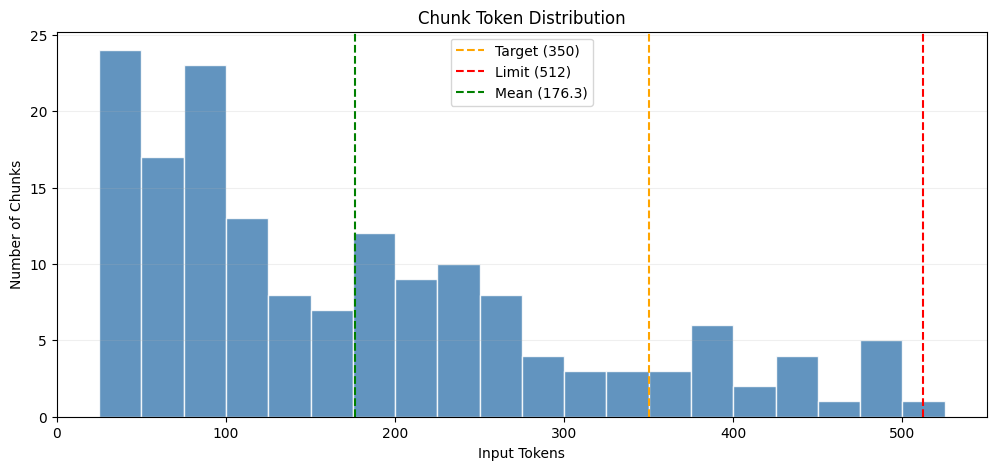

,청크 개수
입력 토큰,
"(-0.001, 50.0]",25
"(50.0, 100.0]",39
"(100.0, 200.0]",40
"(200.0, 350.0]",37
"(350.0, 512.0]",22


In [39]:

# 5.13-A. 청크 토큰 분포 확인

import matplotlib.pyplot as plt

# 그래프 크기 설정
plt.figure(figsize=(12, 5))

# 청크 토큰 분포 설정
plt.hist(
    df_chunks["입력 토큰"],
    bins=range(0, 551, 25),
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

# 목표 청크 크기 표시
plt.axvline(
    CHUNK_SIZE,
    color="orange",
    linestyle="--",
    label=f"Target ({CHUNK_SIZE})"
)

# 최대 입력 토큰 표시
plt.axvline(
    INPUT_TOKEN_LIMIT,
    color="red",
    linestyle="--",
    label=f"Limit ({INPUT_TOKEN_LIMIT})"
)

# 평균 입력 토큰 표시
plt.axvline(
    df_chunks["입력 토큰"].mean(),
    color="green",
    linestyle="--",
    label=f"Mean ({df_chunks['입력 토큰'].mean():.1f})"
)

# 그래프 설정
plt.title("Chunk Token Distribution")
plt.xlabel("Input Tokens")
plt.ylabel("Number of Chunks")
plt.xlim(0, 550)
plt.legend()
plt.grid(axis="y", alpha=0.2)

# 그래프 출력
plt.show()

# 토큰 구간 정의
token_ranges = [0, 50, 100, 200, 350, 512]

# 토큰 구간별 청크 수 계산
token_distribution = pd.cut(
    df_chunks["입력 토큰"],
    bins=token_ranges,
    include_lowest=True
).value_counts().sort_index()

# 토큰 분포 출력
display(token_distribution.to_frame("청크 개수"))


In [40]:

# 5.13-B. 주요 기술문서 청크 확인

# 주요 기술문서 검색어 정의
sample_topics = {
    "배터리 이상": "Battery level failsafe",
    "조종기 연결 손실": "Manual Control Loss Failsafe",
    "GPS 위치 이상": "Position (GNSS)"
}

# 주요 기술문서 청크 확인
for topic, keyword in sample_topics.items():

    # 관련 청크 추출
    sample_chunks = [
        chunk for chunk in chunks
        if chunk.metadata["file_name"] == "safety.md"
        and keyword.lower() in chunk.metadata["section"].lower()
    ]

    # 분석 대상 출력
    print("=" * 80)
    print("분석 대상 :", topic)
    print("관련 청크 수 :", len(sample_chunks))
    print("=" * 80)

    # 청크 존재 여부 확인
    if not sample_chunks:
        print("관련 청크 확인 필요")
        continue

    # 대표 청크 선택
    sample = max(
        sample_chunks,
        key=lambda chunk: chunk.metadata["body_tokens"]
    )

    # 청크 정보 출력
    print("Chunk ID :", sample.metadata["chunk_id"])
    print("문서명 :", sample.metadata["file_name"])
    print("장·절 :", sample.metadata["section"])
    print("입력 토큰 :", sample.metadata["input_tokens"])
    print("문서 버전 :", sample.metadata["version"])
    print("원문 URL :", sample.metadata["source"])

    # 청크 본문 출력
    print("-" * 80)
    print(sample.page_content)
    print()


분석 대상 : 배터리 이상
관련 청크 수 : 5
Chunk ID : safety-s006-c005
문서명 : safety.md
장·절 : Safety (Failsafe) Configuration > Battery Failsafes > Battery level failsafe
입력 토큰 : 375
문서 버전 : v1.17.0
원문 URL : https://docs.px4.io/v1.17/en/config/safety
--------------------------------------------------------------------------------
Safety (Failsafe) Configuration > Battery Failsafes > Battery level failsafe

| Setting                                             | Parameter                                                                    | Description                                                                           |
| --------------------------------------------------- | ---------------------------------------------------------------------------- | ------------------------------------------------------------------------------------- |
| <a id="COM_LOW_BAT_ACT"></a>Failsafe Action         | [COM_LOW_BAT_ACT](../advanced_config/parameter_reference.md#COM_LOW_BAT_ACT) | Warn, Return, or Land base